# The fraud desk

The cost curve that set the operating point, and the labels that arrive late.

> Harborline Bank is fictional. This is a demonstration on generated data and public datasets; no real customer, account or transaction of any real institution appears here.
>
> Nothing here is a credit decision, a fraud determination, a suspicious activity finding or investment advice.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import polars as pl
from ledger_core.manifest import Manifest

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
m = Manifest.load(ROOT / "results" / "manifest.json")
plt.rcParams["figure.figsize"] = (9, 4)

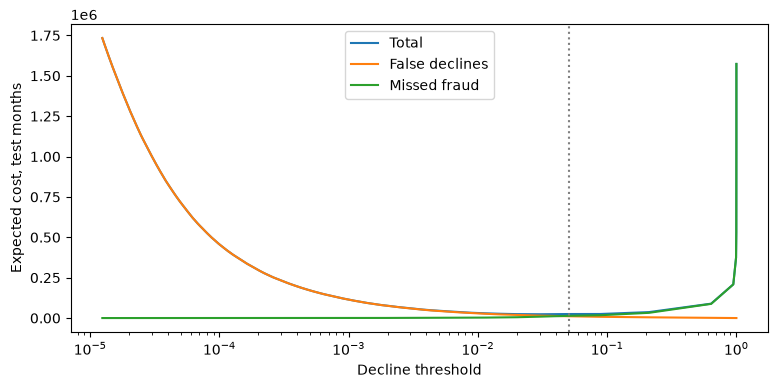

In [2]:
cost = pl.read_parquet(ROOT / "results" / "f04" / "cost_curve.parquet").filter(pl.col("sample") == "test")
fig, ax = plt.subplots()
ax.semilogx(cost["threshold"], cost["total_cost"], label="Total")
ax.semilogx(cost["threshold"], cost["false_decline_cost"], label="False declines")
ax.semilogx(cost["threshold"], cost["missed_fraud_cost"], label="Missed fraud")
ax.axvline(float(m.raw("f04.operating_point")), color="grey", linestyle=":")
ax.set_xlabel("Decline threshold")
ax.set_ylabel("Expected cost, test months")
ax.legend()
plt.show()

In [3]:
lag = pl.read_parquet(ROOT / "results" / "f04" / "label_lag.parquet")
print("Precision over labelled decisions on the as of date:", m.text("models.fraud_card.labelled_precision_as_of"))
print("If unlabelled declines counted as mistakes:", m.text("models.fraud_card.naive_precision_as_of"))
lag.tail(5)

Precision over labelled decisions on the as of date: 73.4%
If unlabelled declines counted as mistakes: 27.0%


day,decisions,labelled,unlabelled,precision_labelled,recall_labelled
date,i64,i64,i64,f64,f64
2026-08-27,457214,261860,195354,0.737916,0.980327
2026-08-28,461246,264034,197212,0.73658,0.980479
2026-08-29,465884,266418,199466,0.736161,0.980558
2026-08-30,470335,269121,201214,0.735214,0.980643
2026-08-31,472370,271801,200569,0.733967,0.980755
